# 01 — Data Exploration
## Urban Taxi Mobility Pattern Discovery — Phase 1

This notebook covers dataset discovery, actual schema detection, loading,
cleaning, trajectory reconstruction diagnostics, and exploratory data
analysis on the **Microsoft Research T-Drive** taxi trajectory dataset.

**All results below are computed from your actual downloaded data.**
If you have not yet downloaded and extracted T-Drive into `data/raw/`,
the cells below will raise a clear `DataLoadError` telling you what to do —
see `README.md` for exact download/extraction steps.


In [1]:
# --- Setup ---
import sys
from pathlib import Path

# Add src/ to the path so we can import project modules from the notebook
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from config import COL_TAXI_ID, COL_TIMESTAMP, COL_LAT, COL_LON
import data_loader
import preprocessing
import trajectory

config.ensure_output_dirs()
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data dir: {config.TDRIVE_RAW_DIR}")


Project root: c:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility
Raw data dir: C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\data\raw


## Part 3 — Data Understanding

We inspect the actual downloaded files before assuming anything about
their structure.

In [2]:
# File count and size
taxi_files = data_loader.find_taxi_files()
total_size_mb = sum(p.stat().st_size for p in taxi_files) / (1024 ** 2)

print(f"File count: {len(taxi_files):,}")
print(f"Total size on disk: {total_size_mb:,.1f} MB")
print(f"First 5 files: {[p.name for p in taxi_files[:5]]}")
print(f"Last 5 files:  {[p.name for p in taxi_files[-5:]]}")


File count: 10,357
Total size on disk: 752.2 MB
First 5 files: ['1.txt', '2.txt', '3.txt', '4.txt', '5.txt']
Last 5 files:  ['10353.txt', '10354.txt', '10355.txt', '10356.txt', '10357.txt']


In [3]:
# Detected schema (NOT assumed) — see data_loader.detect_schema()
schema_report = data_loader.detect_schema(taxi_files, n_check=5)
print("Detected schema:")
for k, v in schema_report.items():
    print(f"  {k}: {v}")


Detected schema:
  files_checked: ['1.txt', '2.txt', '3.txt', '4.txt', '5.txt']
  delimiter: ,
  column_count: 4
  header_detected: False
  sample_lines: ['1,2008-02-02 15:36:08,116.51172,39.92123', '1,2008-02-02 15:46:08,116.51135,39.93883', '2,2008-02-02 13:33:52,116.36422,39.88781', '2,2008-02-02 13:37:16,116.37481,39.88782', '3,2008-02-02 13:39:08,116.35743,39.88957', '3,2008-02-02 13:44:08,116.35732,39.89726', '4,2008-02-02 15:15:04,116.47002,39.90666', '4,2008-02-02 15:25:04,116.44422,39.92078', '5,2008-02-02 13:43:04,116.62934,39.82726', '5,2008-02-02 13:53:04,116.62934,39.82725']


## Part 4 & 5 — Loading a Development Sample

Loading a configurable sample (see `config.SAMPLE_TAXI_COUNT`) rather than
all ~10,357 taxis / ~15M points, to keep development iterations fast.
Raw files under `data/raw/` are never modified — this only reads them.

In [4]:
raw_df = data_loader.load_tdrive_sample()
print(f"\nLoaded shape: {raw_df.shape}")
raw_df.head(10)


Found 10,357 taxi files under C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\data\raw. Loading 100 taxi(s).
Detected schema: {'files_checked': ['107.txt', '410.txt', '435.txt', '489.txt', '521.txt'], 'delimiter': ',', 'column_count': 4, 'header_detected': False, 'sample_lines': ['107,2008-02-02 13:39:21,116.5826,40.06171', '107,2008-02-02 13:47:28,116.58155,40.06951', '410,2008-02-02 13:38:54,116.44736,39.93248', '410,2008-02-02 13:43:54,116.4304,39.93382', '435,2008-02-02 13:54:15,116.5131,39.8905', '435,2008-02-02 14:04:15,116.4835,39.87712', '489,2008-02-02 13:36:25,116.37064,39.99582', '489,2008-02-02 13:41:24,116.37065,39.99572', '521,2008-02-02 13:33:36,116.39875,39.91403', '521,2008-02-02 13:38:11,116.38967,39.90649']}
Loaded 129,545 rows from 100 taxi file(s). 0 file(s) failed to parse.

Loaded shape: (129545, 4)


,taxi_id,timestamp,lon,lat
0,107,2008-02-02 13:39:21,116.58260,40.06171
1,107,2008-02-02 13:47:28,116.58155,40.06951
2,107,2008-02-02 13:53:29,116.58066,40.07391
3,107,2008-02-02 13:53:29,116.58066,40.07391
4,107,2008-02-02 13:58:45,116.58275,40.07463
5,107,2008-02-02 14:06:39,116.58510,40.07667
6,107,2008-02-02 14:23:49,116.58400,40.07687
7,107,2008-02-02 14:26:07,116.58398,40.05345
8,107,2008-02-02 14:28:51,116.56420,40.03410
9,107,2008-02-02 14:28:51,116.56420,40.03410


In [5]:
# Save the untouched raw sample separately (raw/ stays untouched; this is a NEW file)
sample_path = config.SAMPLES_DATA_DIR / "raw_sample.csv"
raw_df.to_csv(sample_path, index=False)
print(f"Saved raw sample to: {sample_path}")


Saved raw sample to: C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\data\samples\raw_sample.csv


### Missing values, duplicates, and date range (on the raw sample)

In [6]:
missing_report = raw_df.isna().sum().to_frame("missing_count")
missing_report["missing_pct"] = 100 * missing_report["missing_count"] / len(raw_df)
print("Missing values per column:")
missing_report


Missing values per column:


,missing_count,missing_pct
taxi_id,0,0.0
timestamp,0,0.0
lon,0,0.0
lat,0,0.0


In [7]:
n_exact_duplicates = raw_df.duplicated().sum()
print(f"Exact duplicate rows in raw sample: {n_exact_duplicates:,} "
      f"({100 * n_exact_duplicates / len(raw_df):.3f}%)")


Exact duplicate rows in raw sample: 11,914 (9.197%)


In [8]:
# Date range — parse timestamps just for reporting (preprocessing.py does the real parsing)
_ts_preview = pd.to_datetime(raw_df[COL_TIMESTAMP], errors="coerce")
print(f"Timestamp parse failures in raw sample: {_ts_preview.isna().sum():,} "
      f"of {len(raw_df):,}")
print(f"Date range: {_ts_preview.min()}  to  {_ts_preview.max()}")


Timestamp parse failures in raw sample: 0 of 129,545
Date range: 2008-02-02 13:31:32  to  2008-02-08 17:39:13


## Part 6 — Data Cleaning

Runs the full pipeline in `src/preprocessing.py` and reports record counts
at every stage.

In [9]:
clean_df, cleaning_report = preprocessing.run_cleaning_pipeline(raw_df)
clean_df.head(10)


Flagged 332 point(s) outside the expected Beijing bounding box (lat (39.4, 41.6), lon (115.4, 117.5)). Not removed unless drop_out_of_region=True.

Data Cleaning Summary
Original records: 129,545
After taxi_id cleaning: 129,545  (removed 0)
After timestamp cleaning: 129,545  (removed 0)
After coordinate validity cleaning: 128,800  (removed 745)
After out-of-region flagging (none dropped): 128,800  (removed 0)
After duplicate removal: 116,913  (removed 11,887)
Final records: 116,913  (removed 0)


,taxi_id,timestamp,lon,lat,in_region
0,10134,2008-02-02 13:42:35,116.35761,39.90600,True
1,10134,2008-02-02 13:52:38,116.34042,39.91870,True
2,10134,2008-02-02 13:55:15,116.34028,39.91757,True
3,10134,2008-02-02 14:00:35,116.34021,39.91747,True
4,10134,2008-02-02 14:15:48,116.34125,39.92185,True
5,10134,2008-02-02 14:20:50,116.34478,39.92675,True
6,10134,2008-02-02 14:25:52,116.33788,39.92960,True
7,10134,2008-02-02 14:35:55,116.32738,39.97409,True
8,10134,2008-02-02 14:40:57,116.32718,39.98123,True
9,10134,2008-02-02 14:45:59,116.31608,39.99094,True


In [10]:
# Save the cleaning summary as a table (outputs/tables/) and the cleaned sample (data/processed/)
cleaning_report.as_dataframe().to_csv(config.TABLES_DIR / "cleaning_summary.csv", index=False)
clean_df.to_csv(config.PROCESSED_DATA_DIR / "cleaned_sample.csv", index=False)
print("Saved cleaning summary and cleaned sample.")


Saved cleaning summary and cleaned sample.


## Part 7 — Trajectory Reconstruction

Derives per-point time gaps, distances, implied speeds, and flags
suspicious GPS jumps (flagged, not removed) using `src/trajectory.py`.

In [11]:
traj_df = trajectory.build_trajectories(clean_df)
diagnostics = trajectory.trajectory_diagnostics(traj_df)

print("Trajectory diagnostics:")
for k, v in diagnostics.items():
    print(f"  {k}: {v:,.3f}" if isinstance(v, float) else f"  {k}: {v:,}")


Trajectory diagnostics:
  n_taxis: 99
  n_points: 116,913
  points_per_taxi_mean: 1,180.939
  points_per_taxi_median: 1,146.000
  points_per_taxi_min: 5
  points_per_taxi_max: 6,397
  time_diff_sec_median: 300.000
  time_diff_sec_mean: 426.887
  distance_m_median: 95.693
  speed_kmh_median: 4.784
  n_suspicious_jumps: 611
  pct_suspicious_jumps: 0.523


In [12]:
traj_df.to_csv(config.PROCESSED_DATA_DIR / "trajectories_sample.csv", index=False)
print("Saved reconstructed trajectories to data/processed/trajectories_sample.csv")


Saved reconstructed trajectories to data/processed/trajectories_sample.csv


## Part 8 — Exploratory Data Analysis

All charts below are computed from the actual cleaned/reconstructed
sample loaded above, and saved to `outputs/figures/`.

In [13]:
# 1. Number of taxis, 2. Number of GPS points, 3. Date range (printed summary)
n_taxis = traj_df[COL_TAXI_ID].nunique()
n_points = len(traj_df)
date_min, date_max = traj_df[COL_TIMESTAMP].min(), traj_df[COL_TIMESTAMP].max()

print(f"Number of taxis (in this sample): {n_taxis:,}")
print(f"Number of GPS points (in this sample): {n_points:,}")
print(f"Date range: {date_min}  to  {date_max}")


Number of taxis (in this sample): 99
Number of GPS points (in this sample): 116,913
Date range: 2008-02-02 13:31:32  to  2008-02-08 17:39:13


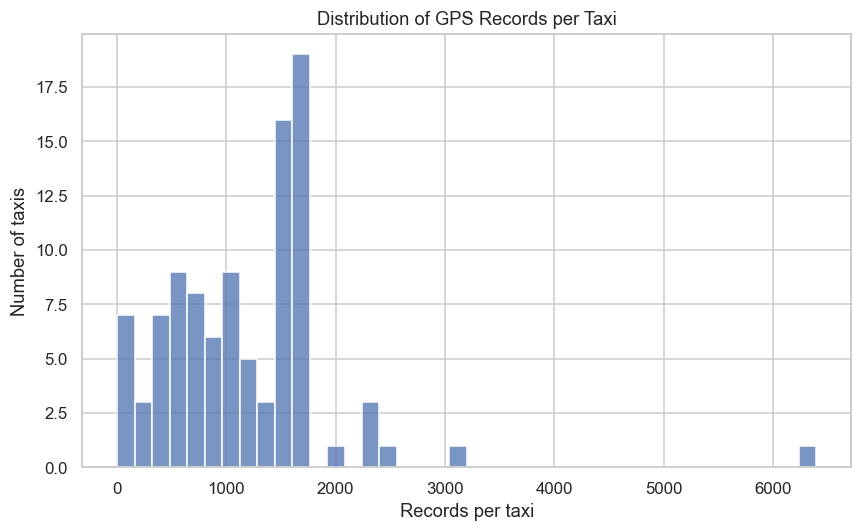

count      99.000000
mean     1180.939394
std       814.484284
min         5.000000
25%       625.000000
50%      1146.000000
75%      1620.000000
max      6397.000000
dtype: float64


In [14]:
# 4. Records per taxi
records_per_taxi = traj_df.groupby(COL_TAXI_ID).size()

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(records_per_taxi, bins=40, ax=ax)
ax.set_title("Distribution of GPS Records per Taxi")
ax.set_xlabel("Records per taxi")
ax.set_ylabel("Number of taxis")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "01_records_per_taxi.png")
plt.show()

print(records_per_taxi.describe())


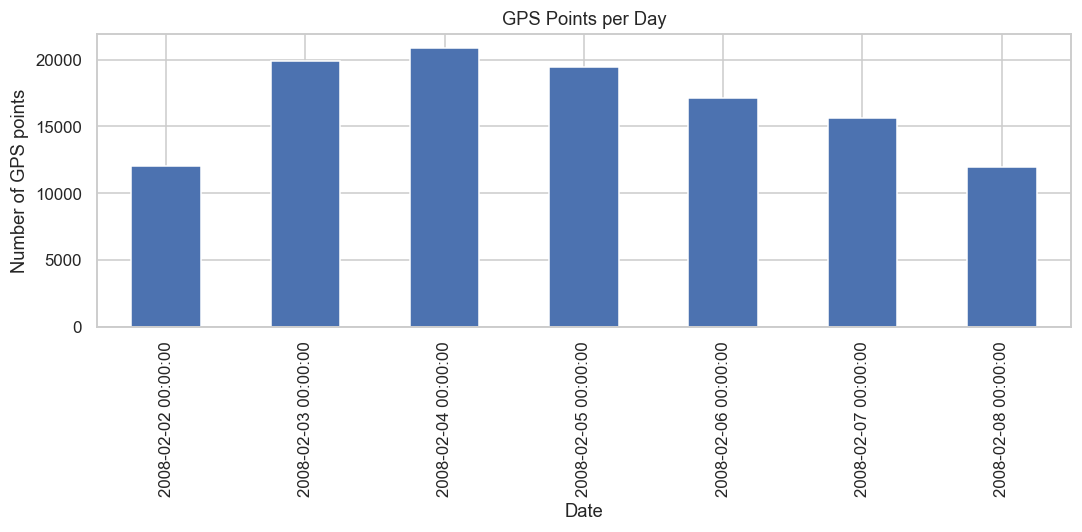

In [15]:
# 5. GPS points per day
points_per_day = traj_df.set_index(COL_TIMESTAMP).resample("D").size()

fig, ax = plt.subplots(figsize=(10, 5))
points_per_day.plot(kind="bar", ax=ax)
ax.set_title("GPS Points per Day")
ax.set_xlabel("Date")
ax.set_ylabel("Number of GPS points")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "02_points_per_day.png")
plt.show()


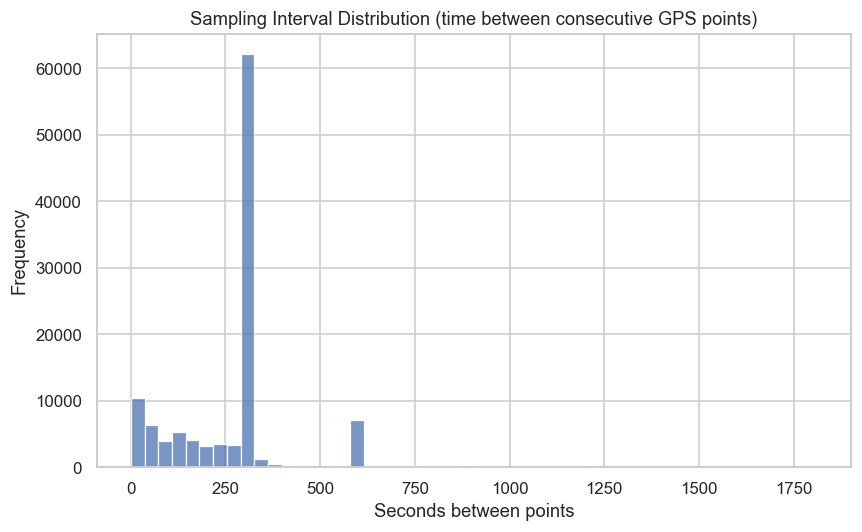

count    116814.000000
mean        426.887205
std        3000.054486
min           0.000000
25%         171.000000
50%         300.000000
75%         301.000000
max      437892.000000
Name: time_diff_sec, dtype: float64


In [16]:
# 6. Sampling interval distribution (time_diff_sec from trajectory reconstruction)
fig, ax = plt.subplots(figsize=(8, 5))
finite_gaps = traj_df["time_diff_sec"].dropna()
finite_gaps = finite_gaps[finite_gaps < finite_gaps.quantile(0.99)]  # trim extreme outliers for readability
sns.histplot(finite_gaps, bins=50, ax=ax)
ax.set_title("Sampling Interval Distribution (time between consecutive GPS points)")
ax.set_xlabel("Seconds between points")
ax.set_ylabel("Frequency")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "03_sampling_interval.png")
plt.show()

print(traj_df["time_diff_sec"].describe())


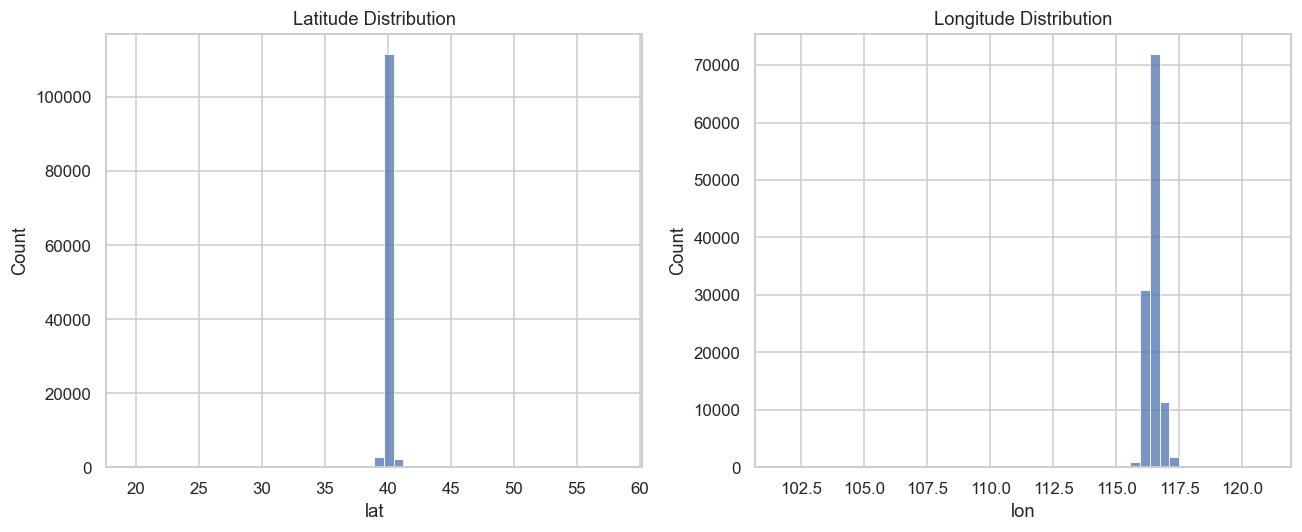

In [17]:
# 7. Latitude distribution, 8. Longitude distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(traj_df[COL_LAT], bins=50, ax=axes[0])
axes[0].set_title("Latitude Distribution")
sns.histplot(traj_df[COL_LON], bins=50, ax=axes[1])
axes[1].set_title("Longitude Distribution")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "04_lat_lon_distribution.png")
plt.show()


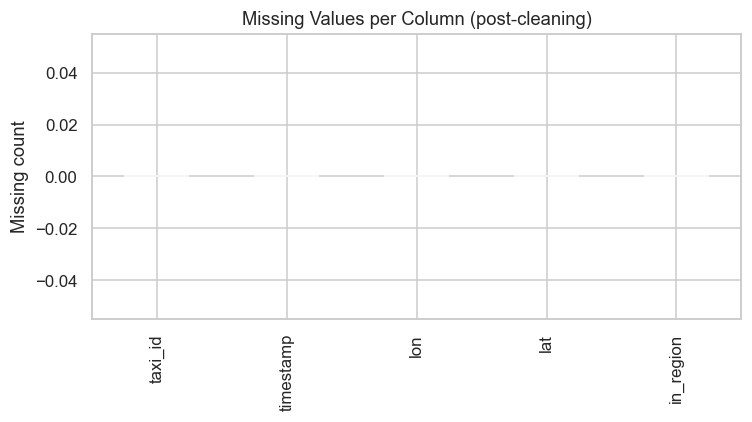

In [18]:
# 9. Missing-value analysis (on cleaned data — should be ~0, confirms cleaning worked)
fig, ax = plt.subplots(figsize=(7, 4))
clean_df.isna().sum().plot(kind="bar", ax=ax)
ax.set_title("Missing Values per Column (post-cleaning)")
ax.set_ylabel("Missing count")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "05_missing_values_post_cleaning.png")
plt.show()


In [19]:
# 10. Duplicate analysis (raw vs cleaned)
dup_comparison = pd.DataFrame({
    "stage": ["Raw sample", "After cleaning"],
    "duplicate_rows": [
        raw_df.duplicated().sum(),
        clean_df.duplicated(subset=[COL_TAXI_ID, COL_TIMESTAMP, COL_LAT, COL_LON]).sum(),
    ],
})
print(dup_comparison)


            stage  duplicate_rows
0      Raw sample           11914
1  After cleaning               0


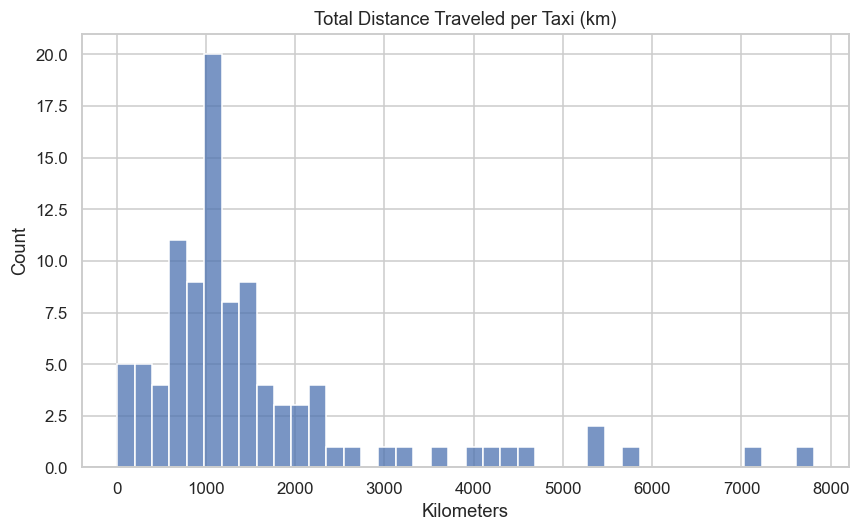

,n_points,total_distance_km,duration_hours
count,99.000000,99.000000,99.000000
mean,1180.939394,1574.051927,139.916953
std,814.484284,1440.550852,26.545565
min,5.000000,6.974263,0.563889
25%,625.000000,779.465849,144.972917
50%,1146.000000,1083.860603,147.863056
75%,1620.000000,1682.745057,147.975417
max,6397.000000,7811.082849,148.099722


In [20]:
# 11. Trajectory length statistics (per-taxi point counts + total distance)
traj_length_stats = traj_df.groupby(COL_TAXI_ID).agg(
    n_points=(COL_TIMESTAMP, "count"),
    total_distance_km=("distance_m", lambda s: s.sum(skipna=True) / 1000),
    duration_hours=(COL_TIMESTAMP, lambda s: (s.max() - s.min()).total_seconds() / 3600),
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(traj_length_stats["total_distance_km"], bins=40, ax=ax)
ax.set_title("Total Distance Traveled per Taxi (km)")
ax.set_xlabel("Kilometers")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "06_trajectory_length_distribution.png")
plt.show()

traj_length_stats.describe()


In [21]:
# Save the trajectory length stats table
traj_length_stats.to_csv(config.TABLES_DIR / "trajectory_length_stats.csv")
print("Saved trajectory length stats to outputs/tables/trajectory_length_stats.csv")


Saved trajectory length stats to outputs/tables/trajectory_length_stats.csv


## Part 9 — Initial Map

Plots a sample of GPS points plus a handful of example full trajectories.
Millions of points are never plotted directly — an explicit sample is
drawn for the point map, and a small number of taxis for the trajectory
lines.

In [22]:
import folium

MAP_POINT_SAMPLE_SIZE = 3000   # cap on individual points plotted
N_EXAMPLE_TRAJECTORIES = 5     # number of full taxi trajectories to draw as lines

center_lat = traj_df[COL_LAT].median()
center_lon = traj_df[COL_LON].median()

m = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles="cartodbpositron")

# Sampled points layer
point_sample = traj_df.sample(
    n=min(MAP_POINT_SAMPLE_SIZE, len(traj_df)), random_state=config.RANDOM_SEED
)
point_layer = folium.FeatureGroup(name=f"Sampled GPS points (n={len(point_sample):,})")
for _, row in point_sample.iterrows():
    folium.CircleMarker(
        location=[row[COL_LAT], row[COL_LON]],
        radius=1.5,
        color="#3186cc",
        fill=True,
        fill_opacity=0.5,
        weight=0,
    ).add_to(point_layer)
point_layer.add_to(m)

# Example trajectory lines layer
example_taxis = traj_df[COL_TAXI_ID].drop_duplicates().sample(
    n=min(N_EXAMPLE_TRAJECTORIES, traj_df[COL_TAXI_ID].nunique()),
    random_state=config.RANDOM_SEED,
)
traj_layer = folium.FeatureGroup(name=f"Example trajectories (n={len(example_taxis)})")
palette = ["#e6194b", "#3cb44b", "#ffe119", "#4363d8", "#f58231", "#911eb4"]
for i, taxi_id in enumerate(example_taxis):
    taxi_points = traj_df[traj_df[COL_TAXI_ID] == taxi_id].sort_values(COL_TIMESTAMP)
    coords = taxi_points[[COL_LAT, COL_LON]].values.tolist()
    folium.PolyLine(coords, color=palette[i % len(palette)], weight=2.5, opacity=0.8,
                     tooltip=f"Taxi {taxi_id}").add_to(traj_layer)
traj_layer.add_to(m)

folium.LayerControl().add_to(m)

map_path = config.MAPS_DIR / "initial_taxi_map.html"
m.save(str(map_path))
print(f"Saved interactive map to: {map_path}")
m


Saved interactive map to: C:\Users\user\Downloads\urban-taxi-mobility\urban-taxi-mobility\outputs\maps\initial_taxi_map.html


## Phase 1 Summary

This notebook has produced, from your actual downloaded data:

- A detected (not assumed) raw file schema
- A cleaned, deduplicated sample with a full cleaning audit trail
  (`outputs/tables/cleaning_summary.csv`)
- Reconstructed trajectories with time/distance/speed diagnostics
  (`data/processed/trajectories_sample.csv`)
- Eleven EDA charts saved to `outputs/figures/`
- An interactive initial map (`outputs/maps/initial_taxi_map.html`)

**Next phase (not started here):** frequent sequential pattern mining,
spatial hotspot detection (DBSCAN), and integration into mobility
corridors. Do not proceed until explicitly instructed.